На линкот е дадено податочно множество со карактерстики за личности и нивната преференца за одмор (1 означува „одмор на планина“, а 0 означува „одмор на плажа“).

- Најнапред, направете Exploratory Data Analysis (EDA) врз податочното множество.
- Потоа, соодветно претпроцесирајте ги податоците.
- На крај, тренирајте и евалуирајте модел по избор за предвидување на преференците врз основа на карактеристиките за личноста.

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import warnings
warnings.filterwarnings('ignore')

# Load the data
df = pd.read_csv('adult.csv')

# Basic information
print("=== BASIC INFORMATION ===")
print(f"Dataset shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())

# Display first few rows
print("\n=== FIRST 5 ROWS ===")
print(df.head())

# Check target variable distribution
print("\n=== TARGET VARIABLE DISTRIBUTION ===")
print(df['income'].value_counts())
print(df['income'].value_counts(normalize=True))

# Summary statistics for numerical features
print("\n=== NUMERICAL FEATURES SUMMARY ===")
numerical_cols = ['age', 'fnlwgt', 'educational-num', 'capital-gain', 'capital-loss', 'hours-per-week']
print(df[numerical_cols].describe())

# Check categorical features
print("\n=== CATEGORICAL FEATURES ===")
categorical_cols = ['workclass', 'education', 'marital-status', 'occupation', 
                   'relationship', 'race', 'gender', 'native-country']
for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts().head(10))

=== BASIC INFORMATION ===
Dataset shape: (48842, 15)
Columns: ['age', 'workclass', 'fnlwgt', 'education', 'educational-num', 'marital-status', 'occupation', 'relationship', 'race', 'gender', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']

Data types:
age                 int64
workclass          object
fnlwgt              int64
education          object
educational-num     int64
marital-status     object
occupation         object
relationship       object
race               object
gender             object
capital-gain        int64
capital-loss        int64
hours-per-week      int64
native-country     object
income             object
dtype: object

Missing values:
age                0
workclass          0
fnlwgt             0
education          0
educational-num    0
marital-status     0
occupation         0
relationship       0
race               0
gender             0
capital-gain       0
capital-loss       0
hours-per-week     0
native-country     0
inc

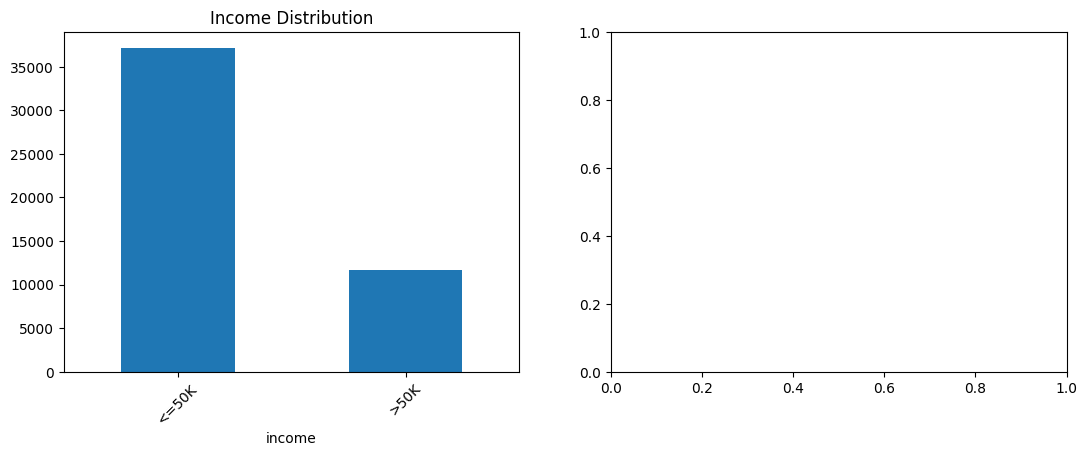

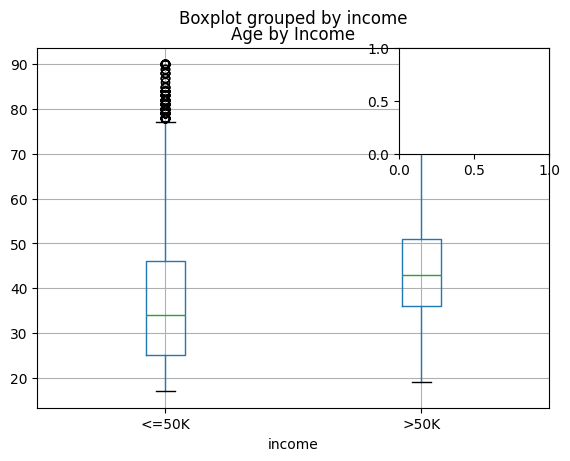

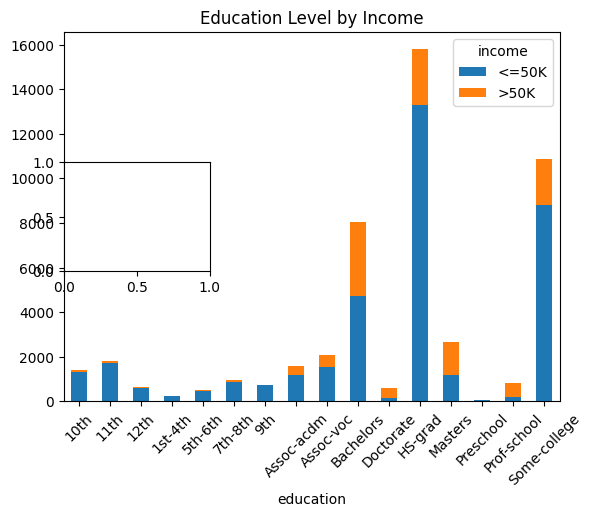

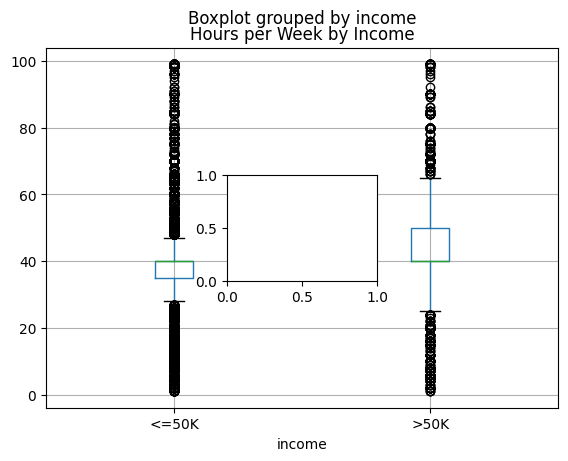

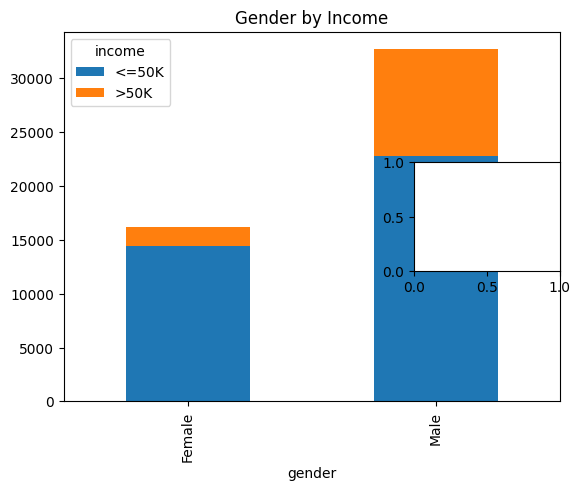

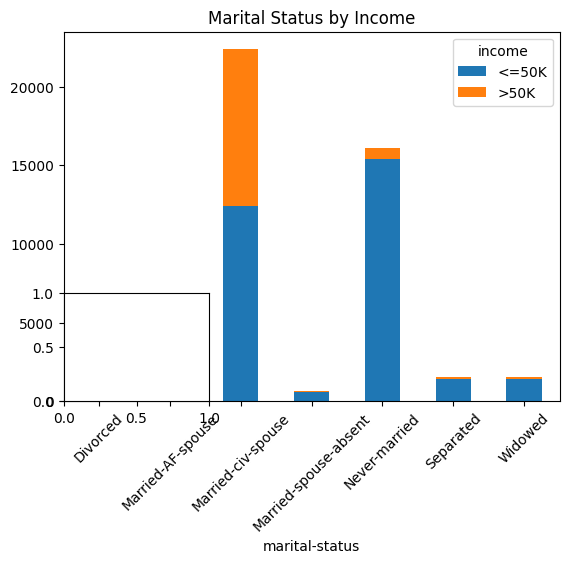

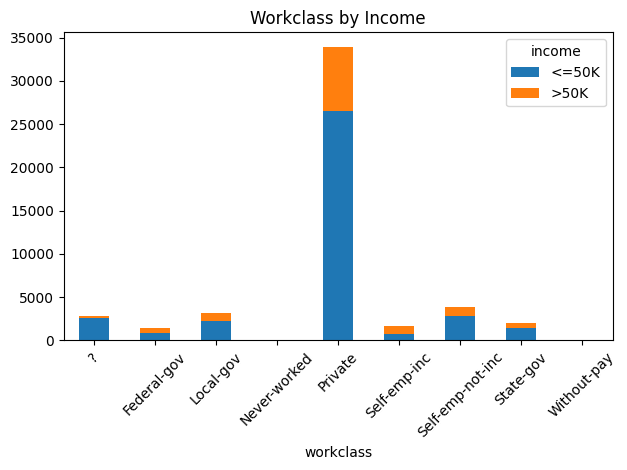

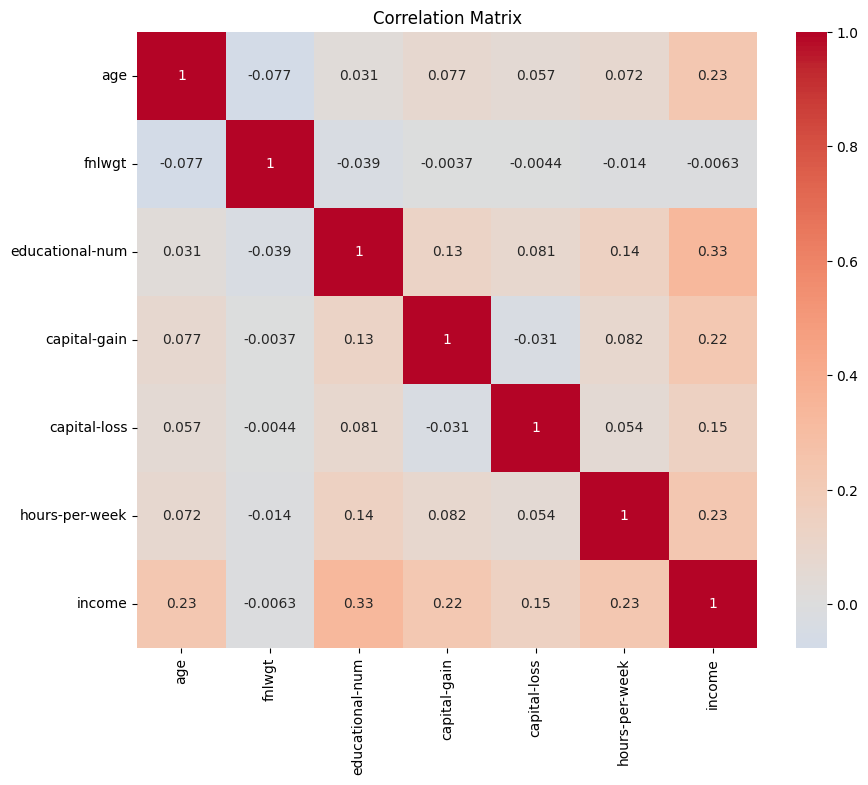

In [52]:
# Visualization
plt.figure(figsize=(20, 15))

# 1. Target distribution
plt.subplot(3, 3, 1)
df['income'].value_counts().plot(kind='bar')
plt.title('Income Distribution')
plt.xticks(rotation=45)

# 2. Age distribution by income
plt.subplot(3, 3, 2)
df.boxplot(column='age', by='income')
plt.title('Age by Income')

# 3. Education level by income
plt.subplot(3, 3, 3)
education_income = pd.crosstab(df['education'], df['income'])
education_income.plot(kind='bar', stacked=True)
plt.title('Education Level by Income')
plt.xticks(rotation=45)

# 4. Hours per week by income
plt.subplot(3, 3, 4)
df.boxplot(column='hours-per-week', by='income')
plt.title('Hours per Week by Income')

# 5. Gender distribution by income
plt.subplot(3, 3, 5)
gender_income = pd.crosstab(df['gender'], df['income'])
gender_income.plot(kind='bar', stacked=True)
plt.title('Gender by Income')

# 6. Marital status by income
plt.subplot(3, 3, 6)
marital_income = pd.crosstab(df['marital-status'], df['income'])
marital_income.plot(kind='bar', stacked=True)
plt.title('Marital Status by Income')
plt.xticks(rotation=45)

# 7. Workclass by income
plt.subplot(3, 3, 7)
workclass_income = pd.crosstab(df['workclass'], df['income'])
workclass_income.plot(kind='bar', stacked=True)
plt.title('Workclass by Income')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Correlation matrix for numerical features
plt.figure(figsize=(10, 8))
correlation_matrix = df[numerical_cols + ['income']].copy()
correlation_matrix['income'] = correlation_matrix['income'].map({'<=50K': 0, '>50K': 1})
sns.heatmap(correlation_matrix.corr(), annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.show()

In [53]:
# Data Preprocessing
def preprocess_data(df):
    df_clean = df.copy()
    
    # Handle missing values (represented as '?')
    for col in df_clean.columns:
        if df_clean[col].dtype == 'object':
            df_clean[col] = df_clean[col].replace('?', np.nan)
    
    # Drop rows with missing values in key columns
    df_clean = df_clean.dropna(subset=['occupation', 'workclass'])
    
    # Fill remaining missing values
    df_clean['native-country'] = df_clean['native-country'].fillna('United-States')
    
    # Encode target variable
    df_clean['income'] = df_clean['income'].map({'<=50K': 0, '>50K': 1})
    
    return df_clean

# Apply preprocessing
df_processed = preprocess_data(df)

print(f"Original shape: {df.shape}")
print(f"Processed shape: {df_processed.shape}")
print(f"Missing values after preprocessing:")
print(df_processed.isnull().sum())

# Prepare features and target
X = df_processed.drop('income', axis=1)
y = df_processed['income']

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nTraining set: {X_train.shape}")
print(f"Test set: {X_test.shape}")
print(f"Target distribution in training set: {y_train.value_counts(normalize=True)}")

# Create preprocessing pipelines
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Define numerical and categorical features
numerical_features = ['age', 'fnlwgt', 'educational-num', 'capital-gain', 'capital-loss', 'hours-per-week']
categorical_features = ['workclass', 'education', 'marital-status', 'occupation', 
                       'relationship', 'race', 'gender', 'native-country']

# Create preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features)
    ])

print("\n=== PREPROCESSING COMPLETE ===")

Original shape: (48842, 15)
Processed shape: (46033, 15)
Missing values after preprocessing:
age                0
workclass          0
fnlwgt             0
education          0
educational-num    0
marital-status     0
occupation         0
relationship       0
race               0
gender             0
capital-gain       0
capital-loss       0
hours-per-week     0
native-country     0
income             0
dtype: int64

Training set: (36826, 14)
Test set: (9207, 14)
Target distribution in training set: income
0    0.75186
1    0.24814
Name: proportion, dtype: float64

=== PREPROCESSING COMPLETE ===


Training the model...

=== MODEL EVALUATION ===
Accuracy: 0.7903

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.76      0.84      6923
           1       0.55      0.89      0.68      2284

    accuracy                           0.79      9207
   macro avg       0.75      0.82      0.76      9207
weighted avg       0.85      0.79      0.80      9207



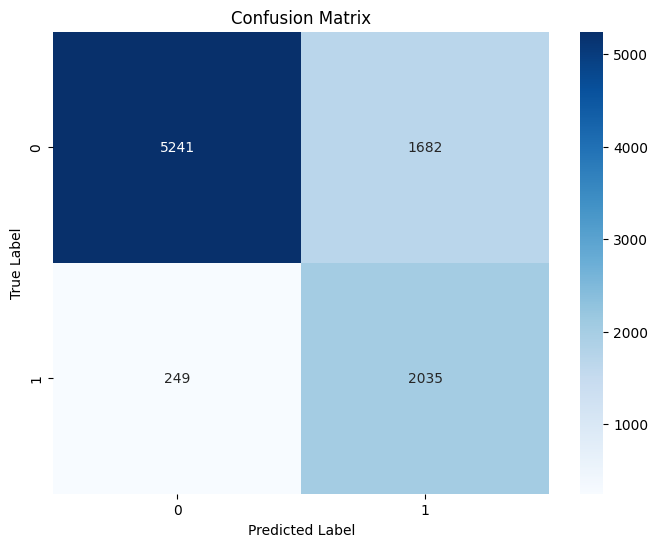


=== TOP 15 FEATURE IMPORTANCES ===
                              feature  importance
28  marital-status_Married-civ-spouse    0.217304
30       marital-status_Never-married    0.118213
2                     educational-num    0.106062
3                        capital-gain    0.104025
0                                 age    0.087619
5                      hours-per-week    0.040477
48             relationship_Own-child    0.040122
46         relationship_Not-in-family    0.038996
55                        gender_Male    0.028686
49             relationship_Unmarried    0.025495
39           occupation_Other-service    0.021092
4                        capital-loss    0.019827
41          occupation_Prof-specialty    0.019567
35         occupation_Exec-managerial    0.017507
20                education_Bachelors    0.012769


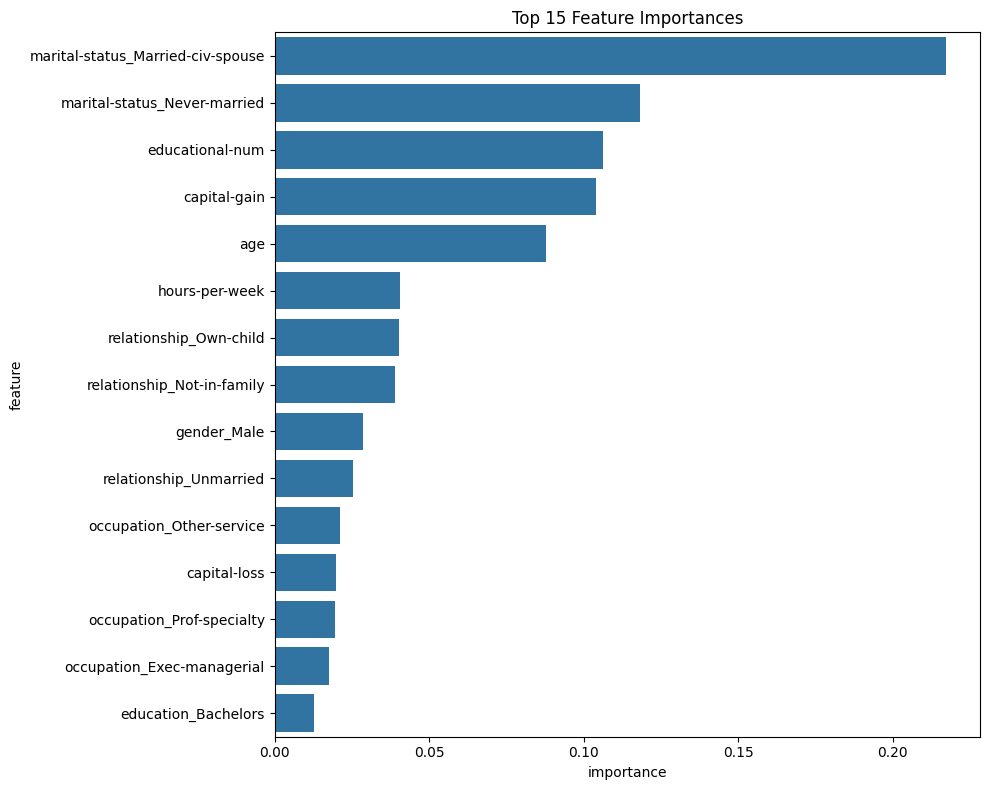


=== ADDITIONAL METRICS ===
ROC-AUC Score: 0.9087
Precision: 0.5475
Recall: 0.8910
F1-Score: 0.6782


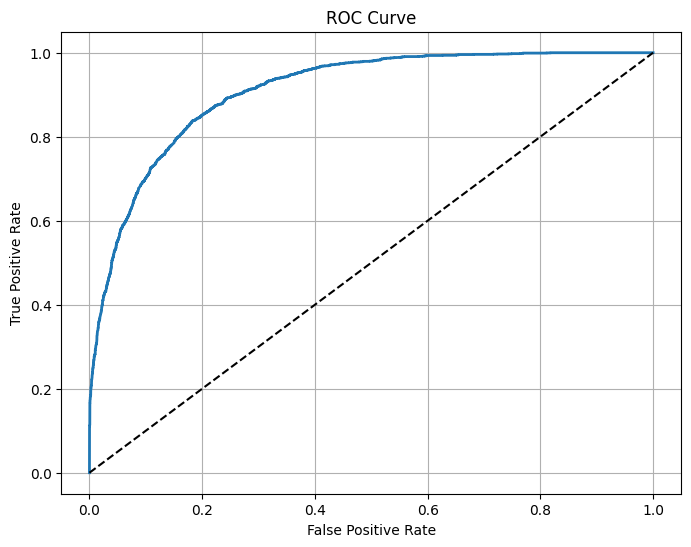

In [54]:
# Create and train model pipeline
from sklearn.ensemble import RandomForestClassifier

# Create pipeline
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        max_depth=10,
        class_weight='balanced'
    ))
])

# Train the model
print("Training the model...")
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("\n=== MODEL EVALUATION ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

# Feature Importance (if available from Random Forest)
feature_importances = model.named_steps['classifier'].feature_importances_

# Get feature names after one-hot encoding
cat_encoder = model.named_steps['preprocessor'].named_transformers_['cat']
cat_feature_names = cat_encoder.get_feature_names_out(categorical_features)
all_feature_names = numerical_features + list(cat_feature_names)

# Create feature importance dataframe
importance_df = pd.DataFrame({
    'feature': all_feature_names,
    'importance': feature_importances
}).sort_values('importance', ascending=False)

print("\n=== TOP 15 FEATURE IMPORTANCES ===")
print(importance_df.head(15))

# Plot feature importances
plt.figure(figsize=(10, 8))
top_features = importance_df.head(15)
sns.barplot(data=top_features, x='importance', y='feature')
plt.title('Top 15 Feature Importances')
plt.tight_layout()
plt.show()

# Additional evaluation metrics
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score

print("\n=== ADDITIONAL METRICS ===")
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall: {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred):.4f}")

# ROC Curve
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, linewidth=2)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.grid(True)
plt.show()